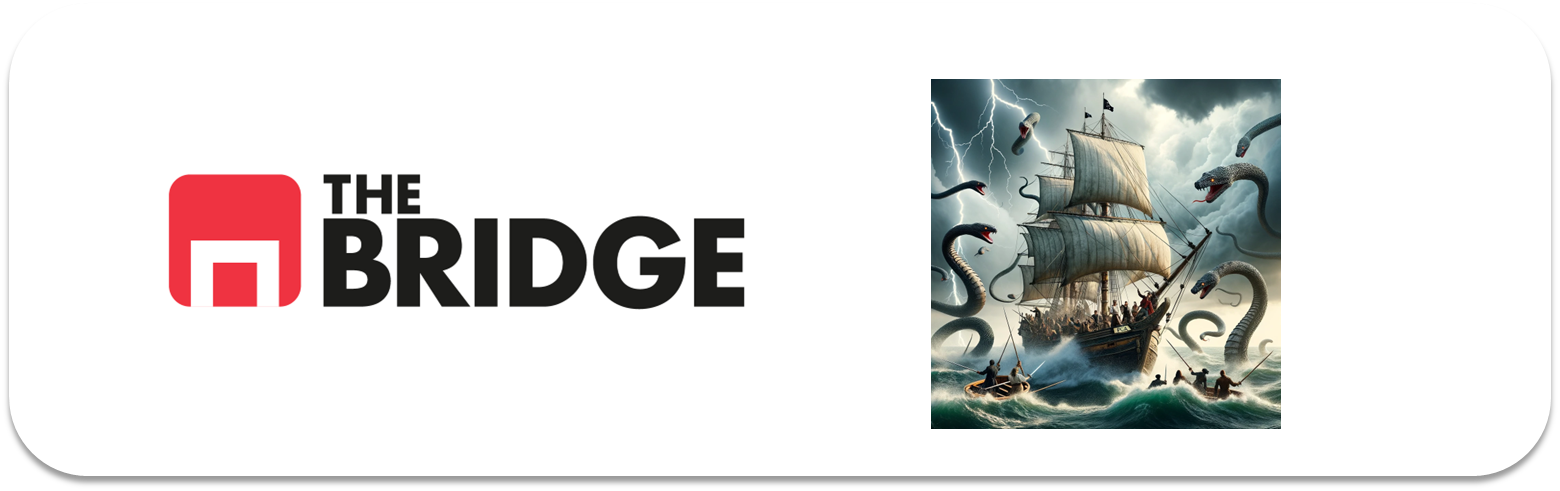

## PRÁCTICA: **No Supervisado: PCA**

* La práctica de esta unidad consiste en aplicar PCA a un dataset de imágenes con diferentes objetivos y compromisos.

### El problema de negocio

El Caesars Palace de Las Vegas está planificando la instalación de mil quinientas microcámaras en los accesos a sus instalaciones para las próximas sesiones del "Poker World Championship". Estas microcámaras tienen la peculiaridad de que son capaces de tomar fotos encuadradas de las caras y la desventaja de que no tienen un gran ancho de banda de comunicación. (Las había de más ancho y de mayor precio...). NOTA: El ancho de banda limita el tamaño de las imágenes que pueden enviar las microcámaras.

El objetivo de las microcámaras es el de detectar personas "non gratas", pudiendo posprocesar las imágenes para poder detectar si han accedido a las instalaciones personas que estuvieran perseguidas por la ley, en los bancos de datos de los casinos identificadas como "peligrosas" (no se sabe si para el resto de personas o para los beneficios de los casinos) y en las listas de no admisión de jugadores adictos. Para ello, necesitan enviar las imágenes a un repositorio central. 

¿Cuál es su problema? O bien comprimen las imágenes y las procesan comprimidas en cada microcámara (pueden comprimir muy rápido pero no tienen CPU para procesarlas sin comprimir) o bien las comprimen y las envían a un servidor central muy potente, donde se descomprimirían y se analizarían. Analizar quiere decir en este contexto pasarles un modelo de clasificación que determine si la persona de la imagen es una de las listas prohibidas (o sea que clasifique la imagen).  

Nos han enviado un dataset y con él debemos estudiar cuál de las dos soluciones es más interesante y dar recomendaciones al respecto. Vamos a ello.

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, recall_score
from sklearn.model_selection import train_test_split, cross_val_score

pd.options.mode.copy_on_write = True # CoW por defecto a partir de pandas 3.0.0

### #1 MODELO DE BASE

**Objetivo:** Construir un modelo baseline de clasificación de imágenes que las trate sin comprimir (es decir, usando todos sus píxeles).

Para conseguir el objetivo, primero descarga el dataset de las caras de Olivetti (400 imágenes en escala de grises de 64x64 píxeles, 10 por cada una de 40 personas), empleando las funciones de sklearn necesarias. Luego, construye un clasificador con el modelo que consideres más apropiado y todas las features del dataset. Eso sí, recuerda hacer lo siguiente:

1. Construir un dataframe con los datos.
2. Hacer un split en train y test con al menos 80 instancias en el test y estratificado según el target. Este split se ha de mantener en el resto de la práctica.
3. Hacer un quick miniEDA o justificar el no hacerlo.
4. Medir el recall medio ("balanced_accuracy") en validación cruzada con 5 folds y en el conjunto de test, y guardar ambos para usarlos como baseline en las siguientes partes.




In [2]:
from sklearn.datasets import fetch_olivetti_faces

olivetti = fetch_olivetti_faces()

In [3]:
olivetti.images.shape

(400, 64, 64)

In [4]:
olivetti.data.shape

(400, 4096)

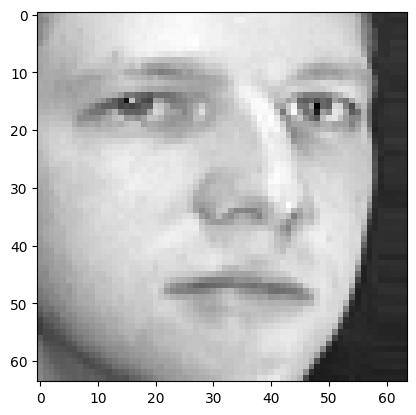

In [5]:
plt.imshow(olivetti.data[4].reshape(64,64), cmap="gray")
plt.show()

In [6]:
df = pd.DataFrame(olivetti.data, columns = [f"pixel_{i}" for i in range(olivetti.data.shape[1])])
df["face_id"] = olivetti.target

target = "face_id"
df

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_4087,pixel_4088,pixel_4089,pixel_4090,pixel_4091,pixel_4092,pixel_4093,pixel_4094,pixel_4095,face_id
0,0.309917,0.367769,0.417355,0.442149,0.528926,0.607438,0.657025,0.677686,0.690083,0.685950,...,0.669421,0.652893,0.661157,0.475207,0.132231,0.148760,0.152893,0.161157,0.157025,0
1,0.454545,0.471074,0.512397,0.557851,0.595041,0.640496,0.681818,0.702479,0.710744,0.702479,...,0.157025,0.136364,0.148760,0.152893,0.152893,0.152893,0.152893,0.152893,0.152893,0
2,0.318182,0.400826,0.491736,0.528926,0.586777,0.657025,0.681818,0.685950,0.702479,0.698347,...,0.132231,0.181818,0.136364,0.128099,0.148760,0.144628,0.140496,0.148760,0.152893,0
3,0.198347,0.194215,0.194215,0.194215,0.190083,0.190083,0.243802,0.404959,0.483471,0.516529,...,0.636364,0.657025,0.685950,0.727273,0.743802,0.764463,0.752066,0.752066,0.739669,0
4,0.500000,0.545455,0.582645,0.623967,0.648760,0.690083,0.694215,0.714876,0.723140,0.731405,...,0.161157,0.177686,0.173554,0.177686,0.177686,0.177686,0.177686,0.173554,0.173554,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.400826,0.495868,0.570248,0.632231,0.648760,0.640496,0.661157,0.636364,0.665289,0.698347,...,0.396694,0.264463,0.099174,0.181818,0.243802,0.247934,0.161157,0.157025,0.136364,39
396,0.367769,0.367769,0.351240,0.301653,0.247934,0.247934,0.367769,0.512397,0.574380,0.628099,...,0.334711,0.289256,0.285124,0.338843,0.404959,0.458678,0.487603,0.512397,0.549587,39
397,0.500000,0.533058,0.607438,0.628099,0.657025,0.632231,0.657025,0.669421,0.673554,0.702479,...,0.148760,0.152893,0.161157,0.161157,0.173554,0.157025,0.177686,0.148760,0.190083,39
398,0.214876,0.219008,0.219008,0.223140,0.210744,0.202479,0.276859,0.400826,0.487603,0.549587,...,0.392562,0.367769,0.409091,0.479339,0.524793,0.545455,0.574380,0.590909,0.603306,39


In [7]:
df.describe()

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_4087,pixel_4088,pixel_4089,pixel_4090,pixel_4091,pixel_4092,pixel_4093,pixel_4094,pixel_4095,face_id
count,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,...,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000,400.000000
mean,0.400134,0.434236,0.476281,0.518481,0.554845,0.588729,0.621426,0.647510,0.664814,0.676591,...,0.367221,0.363027,0.355506,0.340196,0.338657,0.335909,0.321415,0.313647,0.310455,19.500000
std,0.180695,0.189504,0.194742,0.193313,0.188593,0.178481,0.167109,0.155024,0.147616,0.143583,...,0.181861,0.181611,0.188709,0.186088,0.189256,0.195280,0.187842,0.183616,0.180635,11.557853
min,0.086777,0.066116,0.090909,0.041322,0.107438,0.107438,0.115702,0.115702,0.119835,0.140496,...,0.037190,0.053719,0.049587,0.033058,0.012397,0.049587,0.057851,0.061983,0.033058,0.000000
25%,0.243802,0.267562,0.314050,0.383264,0.446281,0.515496,0.544421,0.581612,0.599174,0.611570,...,0.214876,0.219008,0.197314,0.177686,0.177686,0.173554,0.173554,0.173554,0.172521,9.750000
50%,0.392562,0.458678,0.512397,0.545455,0.584711,0.615702,0.652893,0.669421,0.683884,0.702479,...,0.367769,0.342975,0.334711,0.320248,0.314050,0.299587,0.289256,0.270661,0.272727,19.500000
75%,0.528926,0.575413,0.636364,0.666322,0.702479,0.714876,0.735537,0.757231,0.772727,0.780992,...,0.496901,0.500000,0.500000,0.479339,0.462810,0.462810,0.446281,0.414256,0.417355,29.250000
max,0.805785,0.822314,0.871901,0.892562,0.871901,0.871901,0.871901,0.871901,0.871901,0.871901,...,0.904959,0.888430,0.896694,0.826446,0.863636,0.921488,0.929752,0.884298,0.822314,39.000000


In [8]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
pixel_0,400.0,0.400134,0.180695,0.086777,0.243802,0.392562,0.528926,0.805785
pixel_1,400.0,0.434236,0.189504,0.066116,0.267562,0.458678,0.575413,0.822314
pixel_2,400.0,0.476281,0.194742,0.090909,0.314050,0.512397,0.636364,0.871901
pixel_3,400.0,0.518481,0.193313,0.041322,0.383264,0.545455,0.666322,0.892562
pixel_4,400.0,0.554845,0.188593,0.107438,0.446281,0.584711,0.702479,0.871901
...,...,...,...,...,...,...,...,...
pixel_4092,400.0,0.335909,0.195280,0.049587,0.173554,0.299587,0.462810,0.921488
pixel_4093,400.0,0.321415,0.187842,0.057851,0.173554,0.289256,0.446281,0.929752
pixel_4094,400.0,0.313647,0.183616,0.061983,0.173554,0.270661,0.414256,0.884298
pixel_4095,400.0,0.310455,0.180635,0.033058,0.172521,0.272727,0.417355,0.822314


In [9]:
# Barajamos los datos

df_back = df.copy()
df = df_back.sample(len(df_back), random_state=42)
df = df.reset_index(drop=True)
df

,pixel_0,pixel_1,pixel_2,pixel_3,pixel_4,pixel_5,pixel_6,pixel_7,pixel_8,pixel_9,...,pixel_4087,pixel_4088,pixel_4089,pixel_4090,pixel_4091,pixel_4092,pixel_4093,pixel_4094,pixel_4095,face_id
0,0.198347,0.235537,0.351240,0.409091,0.421488,0.429752,0.500000,0.528926,0.524793,0.553719,...,0.508264,0.524793,0.504132,0.483471,0.471074,0.285124,0.061983,0.128099,0.090909,20
1,0.185950,0.128099,0.115702,0.132231,0.185950,0.268595,0.433884,0.541322,0.570248,0.586777,...,0.396694,0.409091,0.301653,0.421488,0.462810,0.247934,0.190083,0.210744,0.210744,28
2,0.508264,0.603306,0.619835,0.628099,0.657025,0.665289,0.690083,0.727273,0.743802,0.768595,...,0.301653,0.305785,0.314050,0.326446,0.338843,0.330579,0.334711,0.342975,0.342975,3
3,0.136364,0.140496,0.185950,0.280992,0.318182,0.363636,0.409091,0.417355,0.438017,0.454545,...,0.169421,0.206612,0.276859,0.355372,0.685950,0.661157,0.280992,0.371901,0.276859,21
4,0.652893,0.644628,0.652893,0.706612,0.714876,0.719008,0.743802,0.747934,0.747934,0.756198,...,0.074380,0.074380,0.082645,0.082645,0.111570,0.070248,0.086777,0.185950,0.231405,9
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
395,0.194215,0.223140,0.314050,0.500000,0.636364,0.735537,0.797521,0.826446,0.847107,0.847107,...,0.206612,0.181818,0.165289,0.123967,0.123967,0.128099,0.136364,0.169421,0.165289,7
396,0.260331,0.355372,0.648760,0.822314,0.838843,0.834711,0.830579,0.826446,0.822314,0.814050,...,0.264463,0.185950,0.136364,0.177686,0.132231,0.103306,0.103306,0.107438,0.119835,10
397,0.611570,0.644628,0.657025,0.669421,0.673554,0.710744,0.735537,0.756198,0.760331,0.768595,...,0.152893,0.107438,0.119835,0.132231,0.111570,0.136364,0.177686,0.210744,0.223140,27
398,0.285124,0.293388,0.297521,0.293388,0.219008,0.107438,0.342975,0.508264,0.533058,0.557851,...,0.388430,0.442149,0.475207,0.500000,0.516529,0.520661,0.533058,0.533058,0.537190,34


In [10]:
train_set, test_set = train_test_split(df, test_size = 80, stratify = df[target], random_state = 42)

*¿Hacer miniEDA? O lo hacemos rápido o no lo hacemos, por dos razones:*

1. Desde el punto de vista de la importancia o relevancia de cada feature: son píxeles, así que hacer un miniEDA para intentar entender cada uno de ellos por separado no tiene mucho sentido. Como mucho, tiene sentido entrenar, por ejemplo, un Random Forest y pintar la importancia de cada píxel, para ver si hay alguno muy muy significativo o muy muy poco significativo.

In [11]:
X_train = train_set.drop(target, axis = 1)
y_train = train_set[target]

X_test = test_set.drop(target, axis = 1)
y_test = test_set[target]

In [12]:
rf_clf_importancia = RandomForestClassifier(random_state = 42)
rf_clf_importancia.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [13]:
rf_clf_importancia.feature_names_in_

array(['pixel_0', 'pixel_1', 'pixel_2', ..., 'pixel_4093', 'pixel_4094',
       'pixel_4095'], dtype=object)

In [14]:
rf_clf_importancia.feature_importances_.cumsum()

array([1.12443026e-04, 2.89824574e-04, 5.53473645e-04, ...,
       9.98365863e-01, 9.99413019e-01, 1.00000000e+00])

In [15]:
len(rf_clf_importancia.feature_importances_)

4096

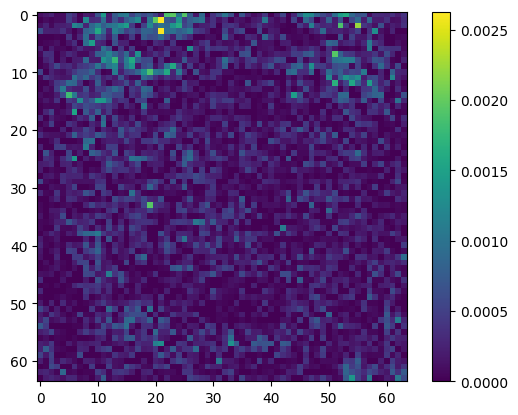

In [16]:
imagen_importancia = rf_clf_importancia.feature_importances_.reshape(64,64)
plt.imshow(imagen_importancia)
plt.colorbar()

*Se ven algunos que destacan un poco más pero dentro de unos rangos de importancia pequeñísimos, así que hacer aquí una selección con criterio es difícil.  
La ventaja de la PCA es que cada componente principal se lleva algo de cada píxel.*

In [17]:
pd.Series(rf_clf_importancia.feature_importances_).describe()

count    4096.000000
mean        0.000244
std         0.000283
min         0.000000
25%         0.000032
50%         0.000168
75%         0.000349
max         0.002628
dtype: float64

2. Del lado de detectar la necesidad de escalar algún píxel:

In [18]:
X_train.describe().T["max"] - X_train.describe().T["min"]

pixel_0       0.719008
pixel_1       0.756198
pixel_2       0.743802
pixel_3       0.814050
pixel_4       0.752066
                ...   
pixel_4091    0.772727
pixel_4092    0.871901
pixel_4093    0.867769
pixel_4094    0.822314
pixel_4095    0.789256
Length: 4096, dtype: float64

In [19]:
df_describe = X_train.describe().T
df_describe

,count,mean,std,min,25%,50%,75%,max
pixel_0,320.0,0.399716,0.177370,0.086777,0.251033,0.388430,0.528926,0.805785
pixel_1,320.0,0.430436,0.187762,0.066116,0.264463,0.454545,0.574380,0.822314
pixel_2,320.0,0.469576,0.193995,0.090909,0.301653,0.504132,0.633264,0.834711
pixel_3,320.0,0.512590,0.191925,0.041322,0.376033,0.545455,0.661157,0.855372
pixel_4,320.0,0.550465,0.188693,0.107438,0.445248,0.578512,0.685950,0.859504
...,...,...,...,...,...,...,...,...
pixel_4091,320.0,0.335615,0.190127,0.012397,0.173554,0.299587,0.463843,0.785124
pixel_4092,320.0,0.332438,0.195619,0.049587,0.173554,0.293388,0.459711,0.921488
pixel_4093,320.0,0.317045,0.187476,0.061983,0.173554,0.278926,0.431818,0.929752
pixel_4094,320.0,0.309452,0.183148,0.061983,0.173554,0.256198,0.409091,0.884298


count    4096.000000
mean        0.693583
std         0.097013
min         0.396694
25%         0.640496
50%         0.706612
75%         0.756198
max         0.938017
Name: rango, dtype: float64


<Axes: xlabel='rango', ylabel='Count'>

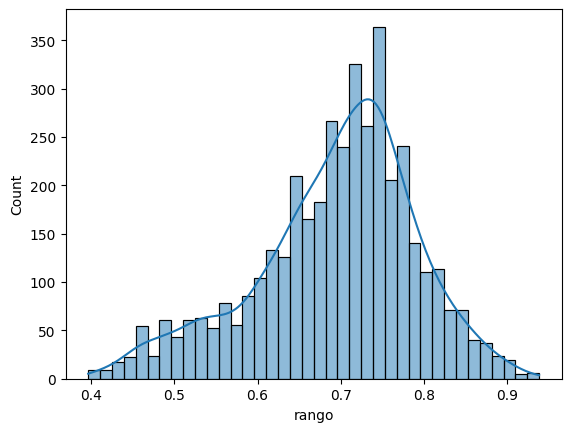

In [20]:
df_describe["rango"] = df_describe["max"] - df_describe["min"]
print(df_describe["rango"].describe())
sns.histplot(df_describe["rango"], kde = True)

<Axes: ylabel='rango'>

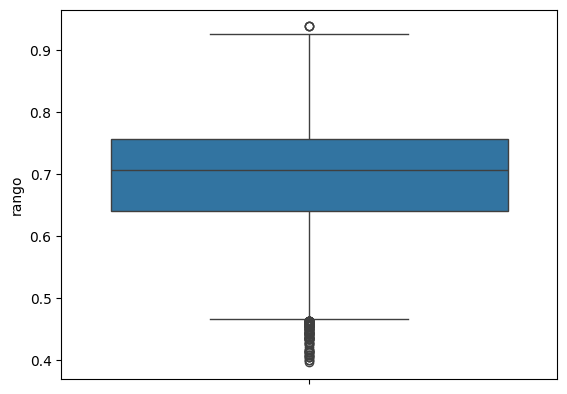

In [21]:
sns.boxplot(df_describe["rango"])

*Los rangos están contenidos entre 0,4 y 0,9 con el 50% de ellos entre 0,63 y 0,75, y la desviación estándar es de 0,09; en definitiva, los rangos son muy parecidos, así que no parece necesario escalar nada.*

*Lo bueno es que ya hemos entrenado el modelo baseline para obtener su rendimiento en test.*


In [22]:
y_pred = rf_clf_importancia.predict(X_test)
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00         2
           1       1.00      1.00      1.00         2
           2       0.67      1.00      0.80         2
           3       1.00      1.00      1.00         2
           4       1.00      1.00      1.00         2
           5       1.00      1.00      1.00         2
           6       1.00      1.00      1.00         2
           7       1.00      1.00      1.00         2
           8       1.00      1.00      1.00         2
           9       1.00      0.50      0.67         2
          10       1.00      1.00      1.00         2
          11       1.00      1.00      1.00         2
          12       1.00      1.00      1.00         2
          13       1.00      1.00      1.00         2
          14       1.00      1.00      1.00         2
          15       1.00      1.00      1.00         2
          16       1.00      1.00      1.00         2
          17       0.67    

In [23]:
# esta es la forma de obtener el recall medio sin copiarlo a ojo
baseline_test = recall_score(y_test, y_pred, average = "macro")
baseline_test


0.95

In [24]:
baseline_cv = np.mean(cross_val_score(rf_clf_importancia, X_train, y_train, cv = 5, scoring = "balanced_accuracy"))
baseline_cv

0.9325000000000001

In [25]:
# Redondeamos un poquito el baseline

baseline_cv = round(baseline_cv, 3)
baseline_cv

0.933

*El hecho de haber obtenido mejor rendimiento en test que en validación cruzada nos "congratula", pero hay que ser un poco pesimistas en esto del data science. Es más probable que en la realidad nuestro modelo se acerque más al resultado de la validación cruzada que al del test. Contemos siempre con el valor más bajo de los dos.*

*Ten en cuenta además que el test tiene solo 80 imágenes (2 por persona): cada imagen mal clasificada son 1,25 puntos porcentuales. Una diferencia de 2-3 pp con el baseline son solo 2 imágenes, así que en las comparaciones que vienen hay bastante ruido.*

### #2 MODELO PARA LAS MICROCÁMARAS
**Objetivo:** Construir un modelo que pueda funcionar en las microcámaras, es decir, que pueda funcionar con datos comprimidos.

Para cumplir con el objetivo se os ocurre emplear la doble propiedad de la PCA, que permite comprimir datos y mantener la capacidad informativa de estos. Sigue los siguientes pasos:
1. Instancia y ajusta un objeto PCA sobre los datos de train sin especificar ni componentes ni varianza explicada (o sea, sin pasar argumentos).
2. Escoge un rango de valores para el número de PCs que permitan por lo menos una compresión de la imagen de entre el 0,2% y el 2,5% (prueba al menos 5 valores). NOTA: La compresión es la reducción total, es decir, una reducción del 1% quiere decir que el dataset se reduce a un 1% de su tamaño original.
3. Para el rango anterior, entrena un modelo de clasificación y apunta su scoring en una validación cruzada de 5 folds, con el recall medio como métrica, y su scoring contra test.
4. Muestra en un dataframe el valor del número de componentes principales empleado, el scoring en CV, el scoring contra test, el % de compresión, la diferencia con el scoring de CV del modelo base, la diferencia con el scoring en test.
5. Escoge el número de componentes que permitirían tener la mayor compresión con una pérdida inferior a 3 puntos porcentuales tanto en CV como en test. Si no hay ninguno, escoge el de mayor compresión con una pérdida inferior a 5 puntos porcentuales. 

In [26]:
X_train.shape

(320, 4096)

In [27]:
pca = PCA() # num entero -> num. de PCs, si float entre 0 y 1 -> el número de PCs para conseguir al menos esa varianza acumulada
pca.fit(X_train)

,"n_components n_components: int, float or 'mle', default=NoneNumber of components to keep.if n_components is not set all components are kept:: n_components == min(n_samples, n_features)If ``n_components == 'mle'`` and ``svd_solver == 'full'``, Minka'sMLE is used to guess the dimension. Use of ``n_components == 'mle'``will interpret ``svd_solver == 'auto'`` as ``svd_solver == 'full'``.If ``0 < n_components < 1`` and ``svd_solver == 'full'``, select thenumber of components such that the amount of variance that needs to beexplained is greater than the percentage specified by n_components.If ``svd_solver == 'arpack'``, the number of components must bestrictly less than the minimum of n_features and n_samples.Hence, the None case results in:: n_components == min(n_samples, n_features) - 1",None
,"copy copy: bool, default=TrueIf False, data passed to fit are overwritten and runningfit(X).transform(X) will not yield the expected results,use fit_transform(X) instead.",True
,"whiten whiten: bool, default=FalseWhen True (False by default) the `components_` vectors are multipliedby the square root of n_samples and then divided by the singular valuesto ensure uncorrelated outputs with unit component-wise variances.Whitening will remove some information from the transformed signal(the relative variance scales of the components) but can sometimeimprove the predictive accuracy of the downstream estimators bymaking their data respect some hard-wired assumptions.",False
,"svd_solver svd_solver: {'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto'""auto"" : The solver is selected by a default 'auto' policy is based on `X.shape` and `n_components`: if the input data has fewer than 1000 features and more than 10 times as many samples, then the ""covariance_eigh"" solver is used. Otherwise, if the input data is larger than 500x500 and the number of components to extract is lower than 80% of the smallest dimension of the data, then the more efficient ""randomized"" method is selected. Otherwise the exact ""full"" SVD is computed and optionally truncated afterwards.""full"" : Run exact full SVD calling the standard LAPACK solver via `scipy.linalg.svd` and select the components by postprocessing""covariance_eigh"" : Precompute the covariance matrix (on centered data), run a classical eigenvalue decomposition on the covariance matrix typically using LAPACK and select the components by postprocessing. This solver is very efficient for n_samples >> n_features and small n_features. It is, however, not tractable otherwise for large n_features (large memory footprint required to materialize the covariance matrix). Also note that compared to the ""full"" solver, this solver effectively doubles the condition number and is therefore less numerical stable (e.g. on input data with a large range of singular values).""arpack"" : Run SVD truncated to `n_components` calling ARPACK solver via `scipy.sparse.linalg.svds`. It requires strictly `0 < n_components < min(X.shape)`""randomized"" : Run randomized SVD by the method of Halko et al... versionadded:: 0.18.0.. versionchanged:: 1.5 Added the 'covariance_eigh' solver.",'auto'
,"tol tol: float, default=0.0Tolerance for singular values computed by svd_solver == 'arpack'.Must be of range [0.0, infinity)... versionadded:: 0.18.0",0.0
,"iterated_power iterated_power: int or 'auto', default='auto'Number of iterations for the power method computed bysvd_solver == 'randomized'.Must be of range [0, infinity)... versionadded:: 0.18.0",'auto'
,"n_oversamples n_oversamples: int, default=10This parameter is only relevant when `svd_solver=""randomized""`.It corresponds to the additional number of random vectors to sample therange of `X` so as to ensure proper conditioning. See:func:`~sklearn.utils.extmath.randomized_svd` for more details... versionadded:: 1.1",10
,"power_iteration_normalizer power_iteration_normalizer: {'auto', 'QR', 'LU', 'none'}, default='auto'Power iteration normalizer for randomized S

In [28]:
X_train.shape

(320, 4096)

*Cabría esperar que nuestra PCA sin argumentos tuviera tantas componentes como features tiene el train, ya que no le hemos puesto restricción y la PCA siempre obtiene tantas componentes principales como features, pero en sklearn...*

In [29]:
len(X_train)

320

In [30]:
pca.n_components_ # num_features >> num_instancias: sklearn obtiene como máximo min(num_instancias, num_features) PCs

320

*Hmmm, ¿qué ha pasado aquí?... Si miras la documentación del constructor de PCA lo entenderás: sin argumentos, sklearn obtiene como máximo `min(n_instancias, n_features)` componentes. Con 320 caras de 4096 píxeles, 320 componentes son suficientes para recoger el 100% de la varianza de train.*

*Nos vale, porque si vemos la varianza acumulada:*

In [31]:
pca.explained_variance_ratio_.cumsum()

array([0.24218807, 0.3826843 , 0.46095803, 0.5113758 , 0.54622835,
       0.579085  , 0.6038183 , 0.62378263, 0.64356625, 0.6602359 ,
       0.67521125, 0.689301  , 0.7023266 , 0.7138658 , 0.7245692 ,
       0.73437303, 0.74383384, 0.7523936 , 0.76029515, 0.76775944,
       0.7747295 , 0.7813285 , 0.78730863, 0.79307646, 0.7984634 ,
       0.8037794 , 0.808892  , 0.8135358 , 0.8181741 , 0.82252806,
       0.8265747 , 0.8304535 , 0.8341706 , 0.8375936 , 0.84090364,
       0.84412307, 0.84722865, 0.8501936 , 0.85311764, 0.855931  ,
       0.8586057 , 0.86119306, 0.8636692 , 0.8660439 , 0.8683779 ,
       0.8706829 , 0.87292796, 0.87512195, 0.877259  , 0.879366  ,
       0.8813918 , 0.8834015 , 0.88533646, 0.8872298 , 0.8890926 ,
       0.89089316, 0.8926366 , 0.89436316, 0.8960343 , 0.8976367 ,
       0.8992061 , 0.90076566, 0.9023083 , 0.9038201 , 0.9052813 ,
       0.90673393, 0.9081569 , 0.9095601 , 0.9109373 , 0.912279  ,
       0.9136158 , 0.9149193 , 0.91619873, 0.9174257 , 0.91864

*Con las 320 PCs se acumula toda.*

Ahora vamos a ver las PCs necesarias para 5 valores entre 0,2% y 2,5% de compresión.

*NOTA: Aquí sí tiene sentido medir la compresión solo como `num_pcs / 4096`. Para descomprimir hacen falta también `components_` y `mean_`, pero se guardan una única vez (en el servidor y en las cámaras) y sirven para todas las imágenes: lo que viaja por la red con cada foto son solo sus proyecciones. Es la diferencia con el ejemplo del perro de la teoría, donde comprimíamos una sola imagen.*

In [32]:
# 0.2% 
# num_pcs / num_total_features = rango

num_features = len(X_train.columns) # Sí, son 4096, por florear un poco
num_pcs = 0.2 * num_features / 100
num_pcs

8.192

In [33]:
# Los rangos que voy a probar
np.linspace(0.2, 2.5, 5)

array([0.2  , 0.775, 1.35 , 1.925, 2.5  ])

In [34]:
compresion_maxima = 0.2
compresion_minima = 2.5

num_pcs = []
num_features = len(X_train.columns) # Sí, son 4096, por florear un poco

for rango in np.linspace(compresion_maxima, compresion_minima, 5):
    # grado de compresión = num_pc/num_features * 100 -> num_pc = grado_compresion * num_features / 100
    num_pc = int(rango * num_features / 100)
    print(f"Para {rango:0.3f}% de compresión, voy a probar {num_pc} PCs")
    num_pcs.append(num_pc)
print("Rangos que voy a probar:")
print(num_pcs)

Para 0.200% de compresión, voy a probar 8 PCs
Para 0.775% de compresión, voy a probar 31 PCs
Para 1.350% de compresión, voy a probar 55 PCs
Para 1.925% de compresión, voy a probar 78 PCs
Para 2.500% de compresión, voy a probar 102 PCs
Rangos que voy a probar:
[8, 31, 55, 78, 102]


*NOTA: `int()` redondea hacia abajo, así que la configuración más comprimida (8 PCs) supone un 0,195% del tamaño original, ligeramente por debajo del 0,2% mínimo que pide el enunciado. Lo aceptamos: la diferencia es mínima y no cambia las conclusiones.*

In [35]:
X_train_pca = pca.transform(X_train) # Devuelve un array de numpy
X_test_pca = pca.transform(X_test) # Con la misma proyección del train, no volvemos a ajustar con test

X_train_pca.shape

(320, 320)

In [36]:
X_test_pca.shape

(80, 320)

In [37]:
num_pcs

[8, 31, 55, 78, 102]

In [38]:
pd.DataFrame(X_train_pca[:,:102])

,0,1,2,3,4,5,6,7,8,9,...,92,93,94,95,96,97,98,99,100,101
0,0.526413,2.222135,1.068338,-1.799263,-0.718517,1.524716,1.440423,-2.113126,1.996855,-0.587921,...,0.409694,0.364424,0.127858,0.152414,-0.046936,0.212169,-0.025341,-0.167164,0.013212,0.045458
1,4.355064,2.870463,-0.259196,2.451993,3.452964,-1.514535,1.363052,0.492711,-0.245776,0.741321,...,0.058027,-0.050006,-0.047627,0.094173,0.195839,0.436121,-0.076451,0.085244,-0.106784,-0.023862
2,4.598118,-0.380961,-0.637662,-0.296071,-0.376375,0.982532,0.795213,-0.804212,-0.506526,0.792182,...,0.004496,-0.137864,-0.322160,0.134777,0.102663,0.156332,0.187861,-0.128681,0.138752,-0.130767
3,-0.847229,-0.746168,-0.085557,-0.634096,0.677877,2.146520,1.798242,-1.140497,1.234232,-0.076508,...,0.529202,-0.451490,0.196262,-0.517808,0.134980,-0.117779,-0.181792,0.075991,-0.600426,-0.199799
4,3.364861,3.805041,-2.646904,-2.462325,-1.136394,1.312314,-0.373386,-1.876120,-1.871610,0.409607,...,-0.281805,0.011969,-0.354317,-0.401695,0.377135,0.086455,0.264721,-0.181751,-0.140019,-0.075838
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
315,-4.455236,1.958485,-2.402827,0.615186,-1.063919,0.293739,1.641575,1.163062,-2.407105,2.074335,...,0.452213,-0.238107,0.335806,0.014074,-0.082715,0.133876,0.217918,0.280674,-0.023609,-0.338334
316,0.224621,2.349910,-0.540400,-3.880446,-0.088332,2.083120,1.070109,1.195135,-3.036243,-0.982557,...,0.141631,-0.489409,0.297195,-0.221701,0.621765,-0.388040,-0.227873,-0.038089,-0.405376,0.559470
317,-10.044880,-0.453791,-0.332879,0.322786,-0.293149,-1.408972,-0.135375,1.448619,-1.582181,0.459674,...,0.681284,0.248386,-0.062071,0.283905,0.219279,0.099944,0.095599,-0.576293,-0.199370,0.378824
318,-2.732204,2.213702,2.782176,-0.212004,1.319136,0.554618,0.233085,1.624686,-1.813933,-1.339303,...,-0.038325,-0.090954,0.065294,-0.249440,-0.140015,0.054365,-0.072336,0.266531,-0.117418,0.141378


In [39]:
pca.explained_variance_ratio_.cumsum()[:102]

array([0.24218807, 0.3826843 , 0.46095803, 0.5113758 , 0.54622835,
       0.579085  , 0.6038183 , 0.62378263, 0.64356625, 0.6602359 ,
       0.67521125, 0.689301  , 0.7023266 , 0.7138658 , 0.7245692 ,
       0.73437303, 0.74383384, 0.7523936 , 0.76029515, 0.76775944,
       0.7747295 , 0.7813285 , 0.78730863, 0.79307646, 0.7984634 ,
       0.8037794 , 0.808892  , 0.8135358 , 0.8181741 , 0.82252806,
       0.8265747 , 0.8304535 , 0.8341706 , 0.8375936 , 0.84090364,
       0.84412307, 0.84722865, 0.8501936 , 0.85311764, 0.855931  ,
       0.8586057 , 0.86119306, 0.8636692 , 0.8660439 , 0.8683779 ,
       0.8706829 , 0.87292796, 0.87512195, 0.877259  , 0.879366  ,
       0.8813918 , 0.8834015 , 0.88533646, 0.8872298 , 0.8890926 ,
       0.89089316, 0.8926366 , 0.89436316, 0.8960343 , 0.8976367 ,
       0.8992061 , 0.90076566, 0.9023083 , 0.9038201 , 0.9052813 ,
       0.90673393, 0.9081569 , 0.9095601 , 0.9109373 , 0.912279  ,
       0.9136158 , 0.9149193 , 0.91619873, 0.9174257 , 0.91864

*NOTA: Por simplicidad ajustamos la PCA con todo el train y luego hacemos la validación cruzada sobre los datos transformados. Como vimos en la teoría, lo riguroso sería meter la PCA en un `Pipeline` para que se reajuste en cada fold; al ser no supervisada, el efecto es pequeño.*

In [40]:
num_pcs

[8, 31, 55, 78, 102]

In [41]:
lista_valores = []

for num_pc in num_pcs:
    X_train_temp = X_train_pca[:,:num_pc] # 
    X_test_temp = X_test_pca[:, :num_pc]

    rf_clf = RandomForestClassifier(random_state = 42)
    eval_cv = np.mean(cross_val_score(rf_clf, X_train_temp, y_train, cv = 5, scoring = "balanced_accuracy"))

    rf_clf.fit(X_train_temp, y_train)
    y_pred = rf_clf.predict(X_test_temp)
    
    eval_test = recall_score(y_test, y_pred, average = "macro")

    datos = {
        "num_pc": num_pc,
        "factor_compresión": round(num_pc/num_features*100,3),
        "eval_cv": round(eval_cv * 100,3),
        "baseline_cv": round(baseline_cv * 100,3),
        "diff_cv": round((baseline_cv - eval_cv) * 100,3),
        "eval_test": round(eval_test * 100,3),
        "baseline_test": round(baseline_test * 100,3),
        "diff_test": round((baseline_test - eval_test) * 100,3),
    }
    
    lista_valores.append(datos.copy())


In [42]:
lista_valores

[{'num_pc': 8,
  'factor_compresión': 0.195,
  'eval_cv': 78.75,
  'baseline_cv': 93.3,
  'diff_cv': 14.55,
  'eval_test': 83.75,
  'baseline_test': 95.0,
  'diff_test': 11.25},
 {'num_pc': 31,
  'factor_compresión': 0.757,
  'eval_cv': 90.75,
  'baseline_cv': 93.3,
  'diff_cv': 2.55,
  'eval_test': 91.25,
  'baseline_test': 95.0,
  'diff_test': 3.75},
 {'num_pc': 55,
  'factor_compresión': 1.343,
  'eval_cv': 91.5,
  'baseline_cv': 93.3,
  'diff_cv': 1.8,
  'eval_test': 95.0,
  'baseline_test': 95.0,
  'diff_test': 0.0},
 {'num_pc': 78,
  'factor_compresión': 1.904,
  'eval_cv': 89.75,
  'baseline_cv': 93.3,
  'diff_cv': 3.55,
  'eval_test': 95.0,
  'baseline_test': 95.0,
  'diff_test': 0.0},
 {'num_pc': 102,
  'factor_compresión': 2.49,
  'eval_cv': 90.25,
  'baseline_cv': 93.3,
  'diff_cv': 3.05,
  'eval_test': 96.25,
  'baseline_test': 95.0,
  'diff_test': -1.25}]

In [43]:
df_resultados = pd.DataFrame(lista_valores)
df_resultados

,num_pc,factor_compresión,eval_cv,baseline_cv,diff_cv,eval_test,baseline_test,diff_test
0,8,0.195,78.75,93.3,14.55,83.75,95.0,11.25
1,31,0.757,90.75,93.3,2.55,91.25,95.0,3.75
2,55,1.343,91.50,93.3,1.80,95.00,95.0,0.00
3,78,1.904,89.75,93.3,3.55,95.00,95.0,0.00
4,102,2.490,90.25,93.3,3.05,96.25,95.0,-1.25


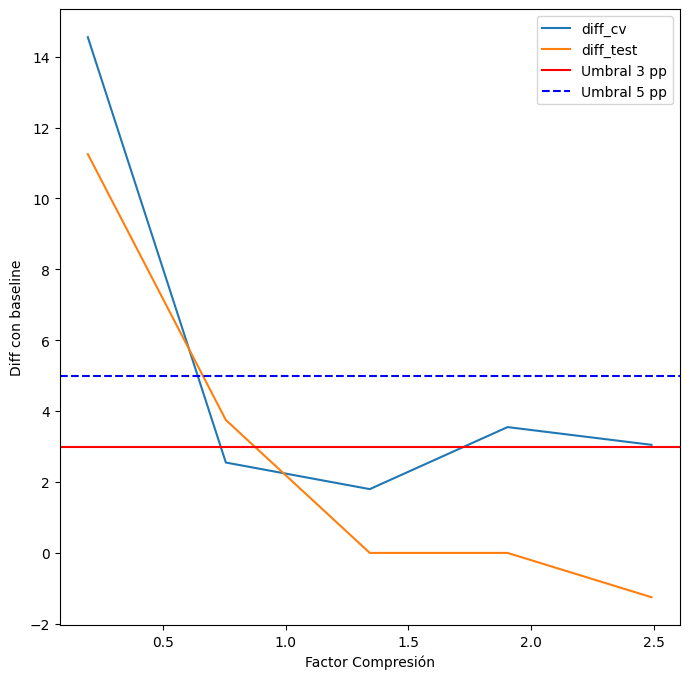

In [44]:
plt.figure(figsize=(8,8))
umbral_corte_1 = 3
umbral_corte_2 = 5

for lineas in ["diff_cv","diff_test"]:
    plt.plot(df_resultados["factor_compresión"], df_resultados[lineas], label = lineas)
plt.xlabel("Factor Compresión")
plt.ylabel("Diff con baseline")
plt.axhline(y = umbral_corte_1, color = 'r', linestyle = '-', label = f"Umbral {umbral_corte_1} pp")
plt.axhline(y = umbral_corte_2, color = "b", linestyle = "--",label = f"Umbral {umbral_corte_2} pp")

plt.legend()
plt.show()

*Dado el enunciado, buscamos las configuraciones que pierden menos de 3 puntos porcentuales tanto en CV como en test:*

In [45]:
# El enunciado pide una pérdida inferior a 3 pp TANTO en CV COMO en test -> & (y), no | (o)
cumple_umbral_1 = (df_resultados["diff_cv"] <= umbral_corte_1) & (df_resultados["diff_test"] <= umbral_corte_1)
df_resultados[cumple_umbral_1]

,num_pc,factor_compresión,eval_cv,baseline_cv,diff_cv,eval_test,baseline_test,diff_test
2,55,1.343,91.5,93.3,1.8,95.0,95.0,0.0


*Solo una configuración cumple las dos condiciones: **55 componentes principales (1,34% del tamaño original)**, que pierde 1,8 pp en CV y nada en test. Fíjate en que 31 PCs, aunque comprime más, pierde 3,75 pp en test y no cumple; y que más componentes no siempre es mejor (78 y 102 PCs pierden más en CV que 55).*

*No hace falta aplicar el criterio de los 5 pp, porque ya tenemos una configuración que cumple el de 3 pp.*

### #3 COMPRESIÓN PARA CLASIFICACIÓN POSTERIOR

**Objetivo**: Obtener el número de componentes que permita comprimir aún más y, al mismo tiempo, que el modelo del servidor central no baje su rendimiento respecto a no usar imágenes comprimidas.

Para esta parte, la idea que se os ha ocurrido es emplear también la PCA como compresor, ya que así siempre podrían pasar a la opción anterior si eso fuese suficiente. Pero en este caso no vamos a utilizar el dataset comprimido con la PCA para detectar las caras, sino el dataset una vez descomprimido (recuerda que puedes emplear `inverse_transform` para "descomprimir"). Los pasos a seguir son:

1. Escoge un rango de valores que permitan una compresión aún mayor (recuerda que el ancho de banda es mínimo) entre el 1 por mil y el 1 por ciento. Escoge 5 valores de número de PCs que permitan movernos en ese rango.
2. Para cada uno de esos valores: aplica la PCA al X_train, obtén un X_train_unzipped aplicando la inversa de la PCA, entrena un modelo de clasificación y apunta su balanced accuracy en una validación cruzada de 5 folds y contra test.
3. Crea un dataframe o haz una visualización comparando cómo es la balanced accuracy para cada número de PCs escogido y cuál es su factor de compresión. 
4. Escoge el número de componentes que permita la mayor compresión con una pérdida inferior a 3 puntos porcentuales respecto al baseline, tanto en CV como en test. Si no hay ninguno, escoge el de mayor compresión con una pérdida inferior a 5 puntos porcentuales.

In [46]:
np.linspace(0.1, 1, 5)

array([0.1  , 0.325, 0.55 , 0.775, 1.   ])

In [47]:
compresion_maxima = 0.1
compresion_minima = 1

num_pcs = []
num_features = len(X_train.columns) # Sí, son 4096, por florear un poco

for rango in np.linspace(compresion_maxima, compresion_minima, 5):
    # grado de compresión = num_pc/num_features * 100 -> num_pc = grado_compresion * num_features / 100
    num_pc = int(rango * num_features/100)
    num_pcs.append(num_pc)
    
print("Rangos que voy a probar:")
print(num_pcs)

Rangos que voy a probar:
[4, 13, 22, 31, 40]


*NOTA: Igual que en la parte 2, por simplicidad ajustamos la PCA con todo el train y hacemos la validación cruzada sobre los datos ya comprimidos y descomprimidos. Lo riguroso sería reajustar la PCA en cada fold; al ser no supervisada, el efecto es pequeño, pero conviene tenerlo en cuenta al leer los resultados de CV.*

In [48]:
lista_valores = []

for num_pc in num_pcs:
    # Por una cuestión de funcionamiento de la clase PCA tenemos que "comprimir" de nuevo: no podemos usar el X_train_pca directamente
    # Con 4096 features sklearn usa un método aleatorizado: fijamos la semilla para que los resultados sean reproducibles
    pca_temp = PCA(num_pc, random_state = 42)
    X = pca_temp.fit_transform(X_train)
    X_t = pca_temp.transform(X_test)
    
    X_train_temp = pca_temp.inverse_transform(X) # AQUÍ ESTÁ LA CLAVE, primero nos quedamos con el dataset pequeño y luego "descomprimimos"
    print("num pcas:", num_pc, "num features descomprimidas: ", X_train_temp.shape[1])
    X_test_temp = pca_temp.inverse_transform(X_t) # APLICAMOS lo mismo a test

    rf_clf = RandomForestClassifier(random_state = 42)
    eval_cv = np.mean(cross_val_score(rf_clf, X_train_temp, y_train, cv = 5, scoring = "balanced_accuracy"))

    rf_clf.fit(X_train_temp, y_train)
    y_pred = rf_clf.predict(X_test_temp)
    eval_test = recall_score(y_test, y_pred, average = "macro")

    datos = {
        "num_pc": num_pc,
        "factor_compresión": round(num_pc/num_features*100,2),
        "eval_cv": round(eval_cv * 100,2),
        "baseline_cv": round(baseline_cv * 100,2),
        "diff_cv": round((baseline_cv - eval_cv) * 100,2),
        "eval_test": round(eval_test * 100,2),
        "baseline_test": round(baseline_test * 100,2),
        "diff_test": round((baseline_test - eval_test) * 100,2),
    }
    
    lista_valores.append(datos.copy())


num pcas: 4 num features descomprimidas:  4096


num pcas: 13 num features descomprimidas:  4096


num pcas: 22 num features descomprimidas:  4096


num pcas: 31 num features descomprimidas:  4096


num pcas: 40 num features descomprimidas:  4096


In [49]:
df_resultados = pd.DataFrame(lista_valores)
df_resultados

,num_pc,factor_compresión,eval_cv,baseline_cv,diff_cv,eval_test,baseline_test,diff_test
0,4,0.10,62.25,93.3,31.05,65.00,95.0,30.00
1,13,0.32,84.75,93.3,8.55,87.50,95.0,7.50
2,22,0.54,90.50,93.3,2.80,88.75,95.0,6.25
3,31,0.76,89.50,93.3,3.80,91.25,95.0,3.75
4,40,0.98,90.25,93.3,3.05,91.25,95.0,3.75


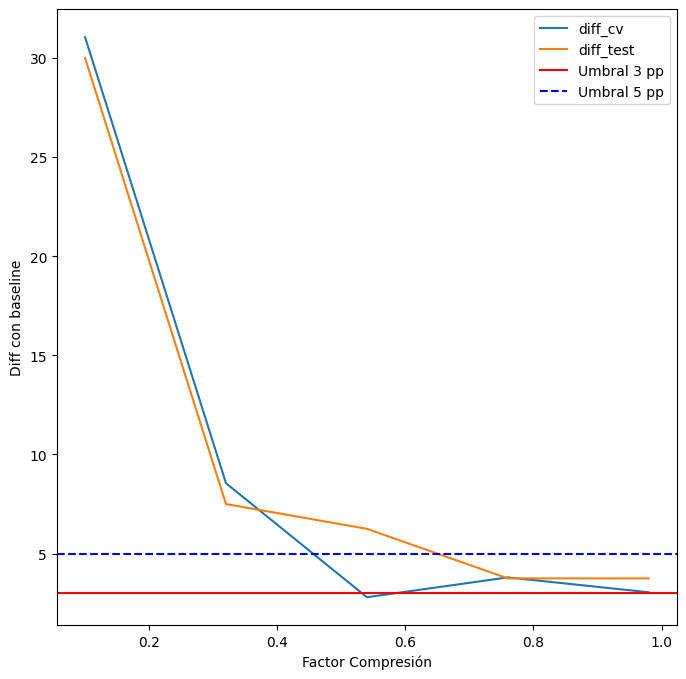

In [50]:
plt.figure(figsize=(8,8))
umbral_corte_1 = 3
umbral_corte_2 = 5

for lineas in ["diff_cv","diff_test"]:
    plt.plot(df_resultados["factor_compresión"], df_resultados[lineas], label = lineas)
plt.xlabel("Factor Compresión")
plt.ylabel("Diff con baseline")
plt.axhline(y = umbral_corte_1, color = 'r', linestyle = '-', label = f"Umbral {umbral_corte_1} pp")
plt.axhline(y = umbral_corte_2, color = "b", linestyle = "--",label = f"Umbral {umbral_corte_2} pp")

plt.legend()
plt.show()

In [51]:
# Criterio principal: perder menos de 3 pp respecto al baseline, tanto en CV como en test
cumple_umbral_1 = (df_resultados["diff_cv"] <= umbral_corte_1) & (df_resultados["diff_test"] <= umbral_corte_1)
df_resultados[cumple_umbral_1]

,num_pc,factor_compresión,eval_cv,baseline_cv,diff_cv,eval_test,baseline_test,diff_test


*Ninguna configuración cumple el criterio de 3 pp, así que aplicamos el de respaldo, 5 pp:*

In [52]:
cumple_umbral_2 = (df_resultados["diff_cv"] <= umbral_corte_2) & (df_resultados["diff_test"] <= umbral_corte_2)
df_resultados[cumple_umbral_2]

,num_pc,factor_compresión,eval_cv,baseline_cv,diff_cv,eval_test,baseline_test,diff_test
3,31,0.76,89.50,93.3,3.80,91.25,95.0,3.75
4,40,0.98,90.25,93.3,3.05,91.25,95.0,3.75


*Con el criterio de respaldo cumplen 31 y 40 PCs. Nos quedamos con **31 componentes principales (0,76% del tamaño original)**, la de mayor compresión: pierde unos 4 pp tanto en CV como en test (unas 3 imágenes de test). Por debajo, 22 PCs ya pierde más de 6 pp en test, y con 13 o menos el rendimiento cae claramente.*

### #4 RECOMENDACIÓN FINAL

Compara las soluciones de la parte 2 (procesar las imágenes comprimidas en las microcámaras) y de la parte 3 (comprimir, enviar y descomprimir en el servidor central): ¿qué recomendarías al Caesars Palace y por qué? Ten en cuenta la compresión conseguida (el ancho de banda), la pérdida de rendimiento y lo fiables que son tus medidas (¿cuántas imágenes hay en test?).

*Tenemos dos opciones viables, y la elección es un compromiso de negocio:*

| Opción | PCs | Tamaño enviado | Pérdida CV | Pérdida test |
|---|---|---|---|---|
| Parte 2: procesar comprimido en la cámara | 55 | 1,34% | 1,8 pp | 0 pp |
| Parte 3: descomprimir en el servidor | 31 | 0,76% | 3,8 pp | 3,75 pp |

* *Si **el rendimiento es prioritario**, la opción de la parte 2 con 55 PCs no pierde prácticamente nada respecto al baseline. Además, esas mismas 55 proyecciones podrían enviarse también al servidor, así que una única configuración serviría para las dos modalidades sin tocar los modelos de las microcámaras.*
* *Si **el ancho de banda es el cuello de botella**, la parte 3 con 31 PCs envía casi la mitad de datos por imagen a cambio de unos 4 pp de recall medio.*
* *En ambos casos, ojo con la fiabilidad: el test tiene solo 80 imágenes (1,25 pp por imagen) y las diferencias entre configuraciones son de pocas imágenes. Antes de decidir convendría validar con más datos (más imágenes por persona) o repetir la evaluación con varias semillas.*

*Nuestra recomendación: la opción de la parte 2 con 55 PCs, salvo que el ancho de banda disponible no permita enviar el 1,34% de cada imagen.*

### #EXTRA

Para la tercera parte crea una función que permita ver la cara sin comprimir y la cara después de haberla descomprimido (pista: cada fila del dataset es una cara de 64x64 píxeles aplanada, usa `reshape` y `plt.imshow` con `cmap="gray"`) y haz una comprobación de cómo quedan (visualiza 5 caras por ejemplo) para cada uno de los números de PCs probados. Añade el caso para 150 y 320 PCs para que se vea que, con suficientes componentes, las caras descomprimidas son prácticamente idénticas a las originales.

*Con una función auxiliar que pinta las caras, vamos a visualizar qué ocurre cuando comprimimos y descomprimos nuestros datos con PCA, de forma que entendamos a qué nos referimos cuando hablamos de perder información/varianza.*

In [53]:
def pinta_caras(faces,n_cols = 5, title = ""):
    faces = faces.reshape(-1, 64, 64)
    n_rows = ((len(faces) - 1) // n_cols + 1)
    plt.figure(figsize=(n_cols * 4, n_rows * 4.4))
    for index, face in enumerate(faces):
        plt.subplot(n_rows, n_cols, index + 1)
        plt.imshow(face, cmap="gray")
        plt.axis("off")
    plt.suptitle(title)
    plt.show()


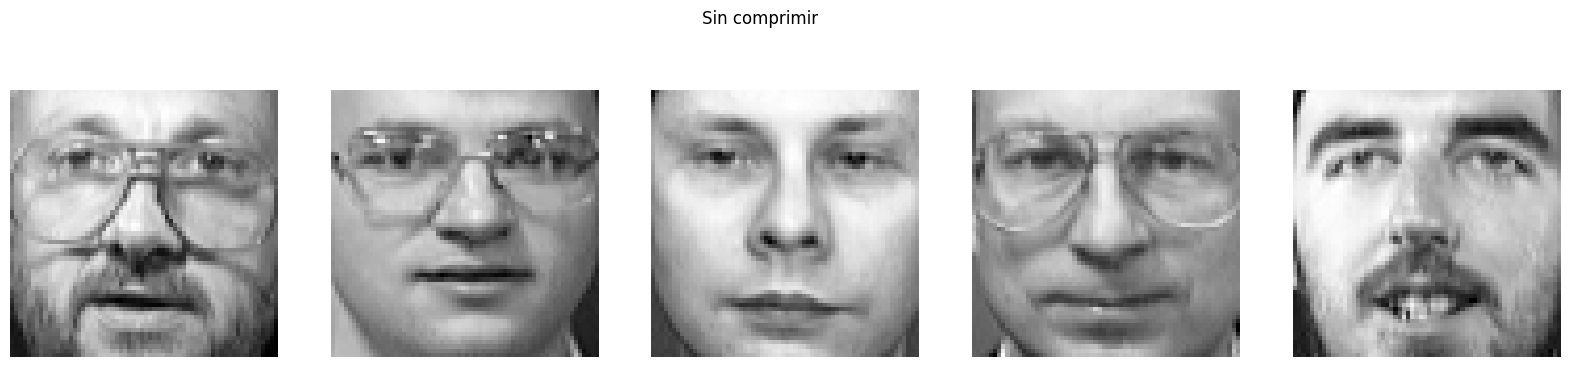

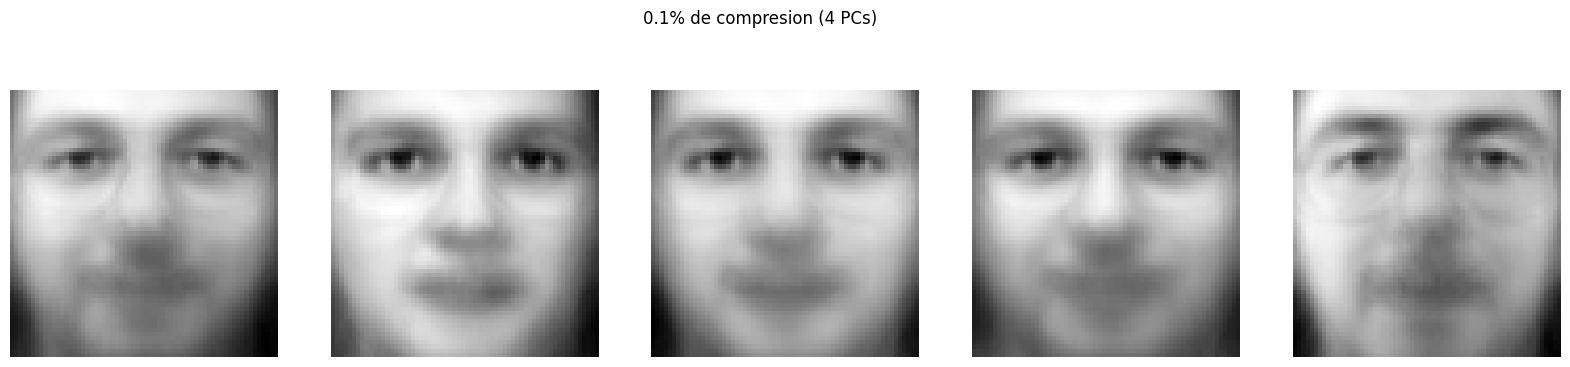

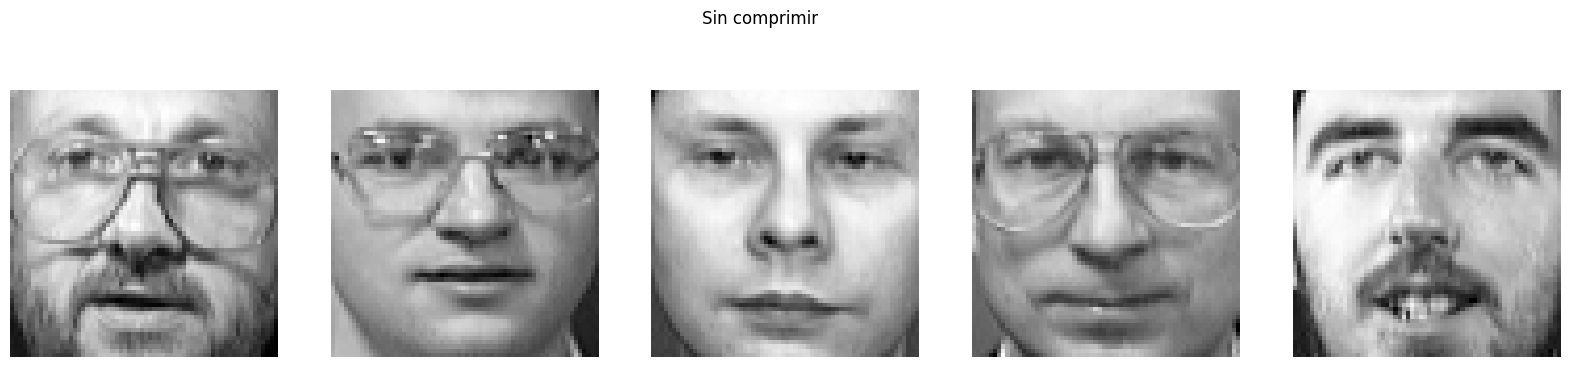

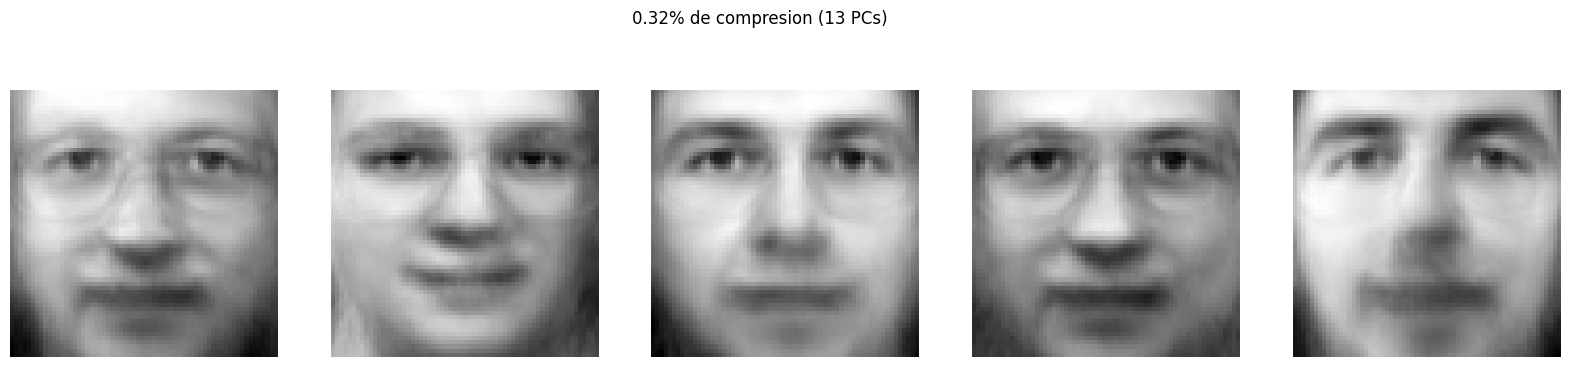

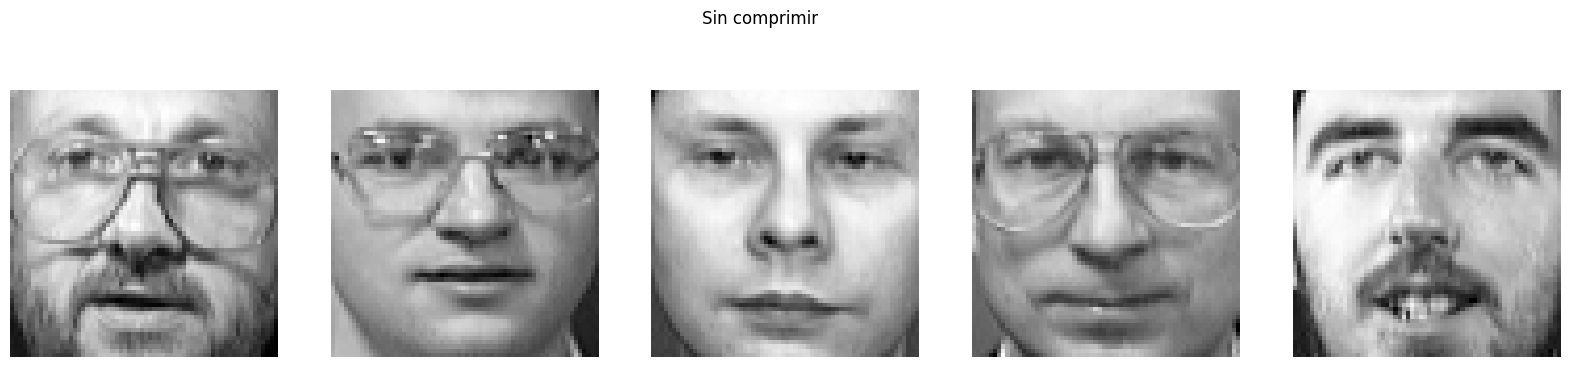

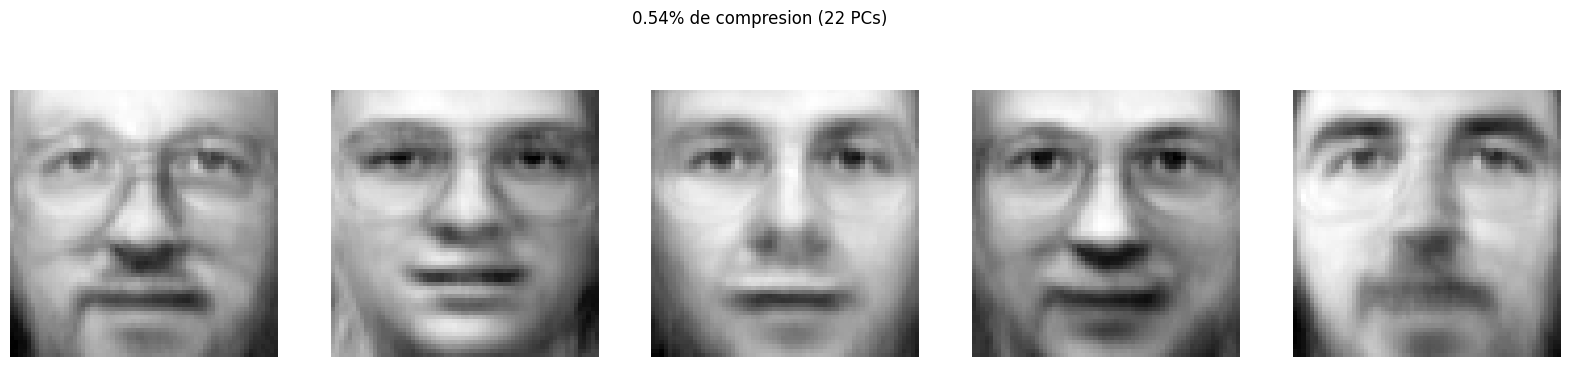

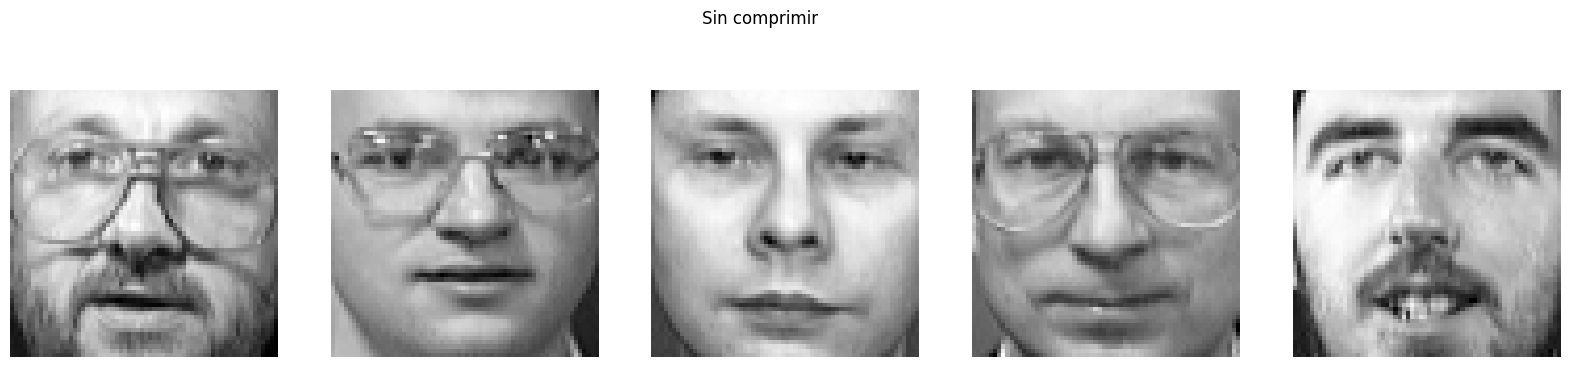

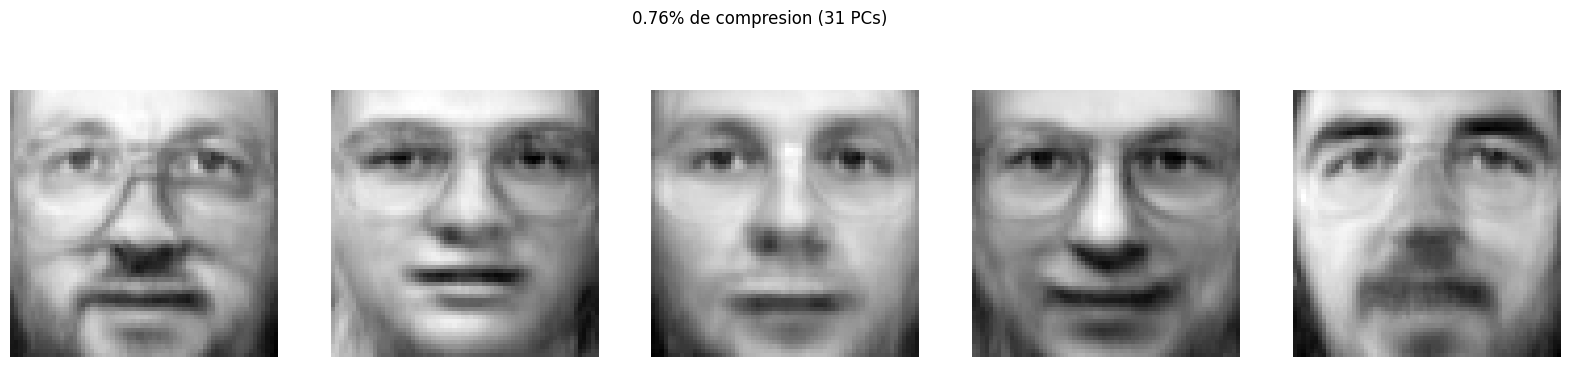

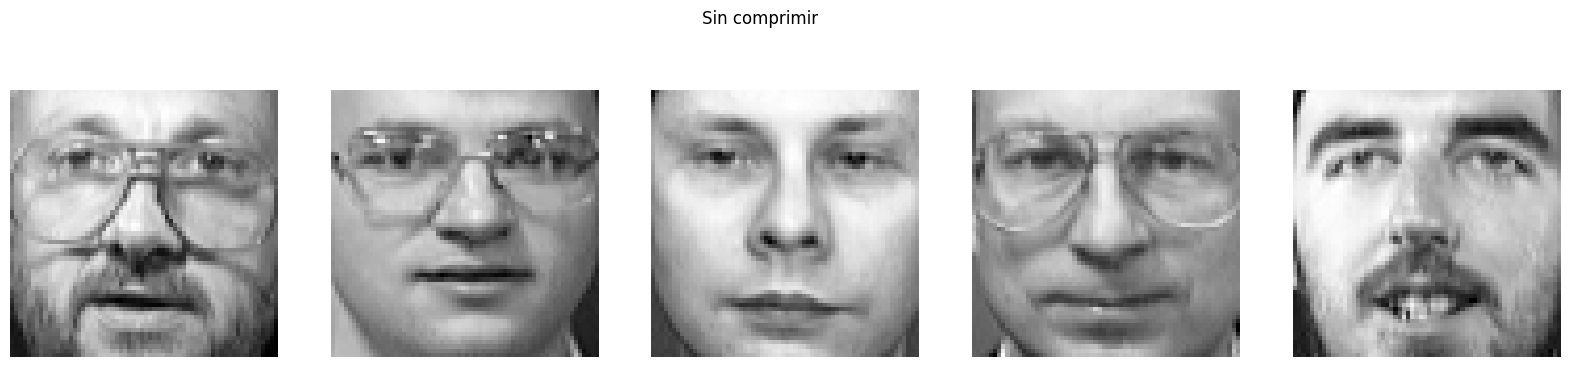

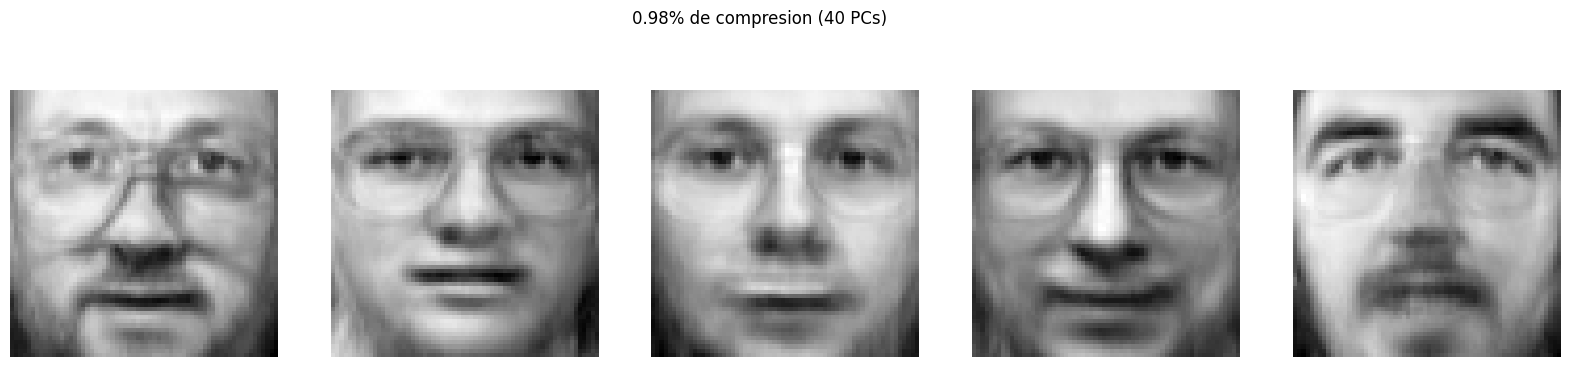

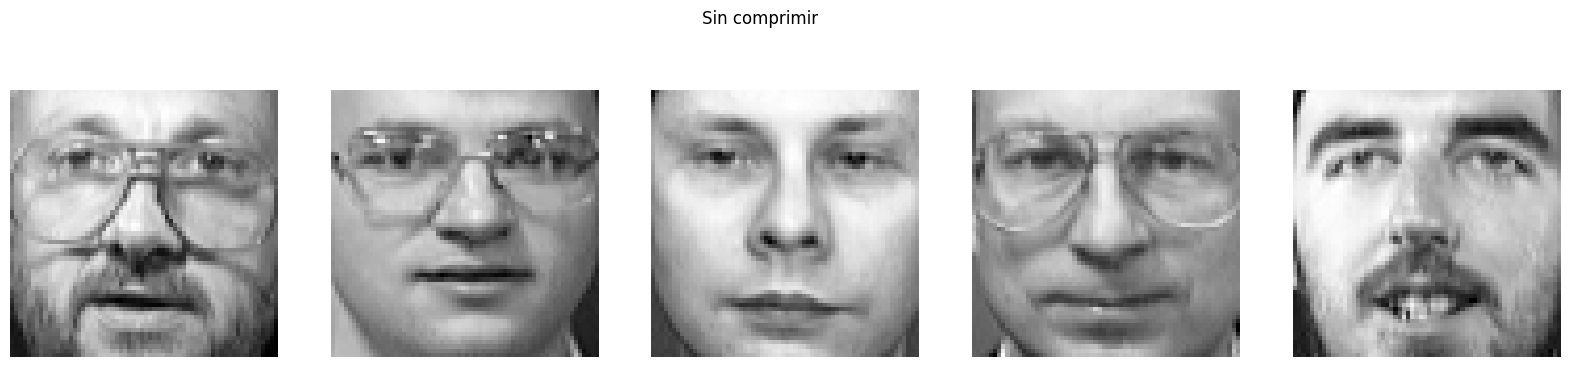

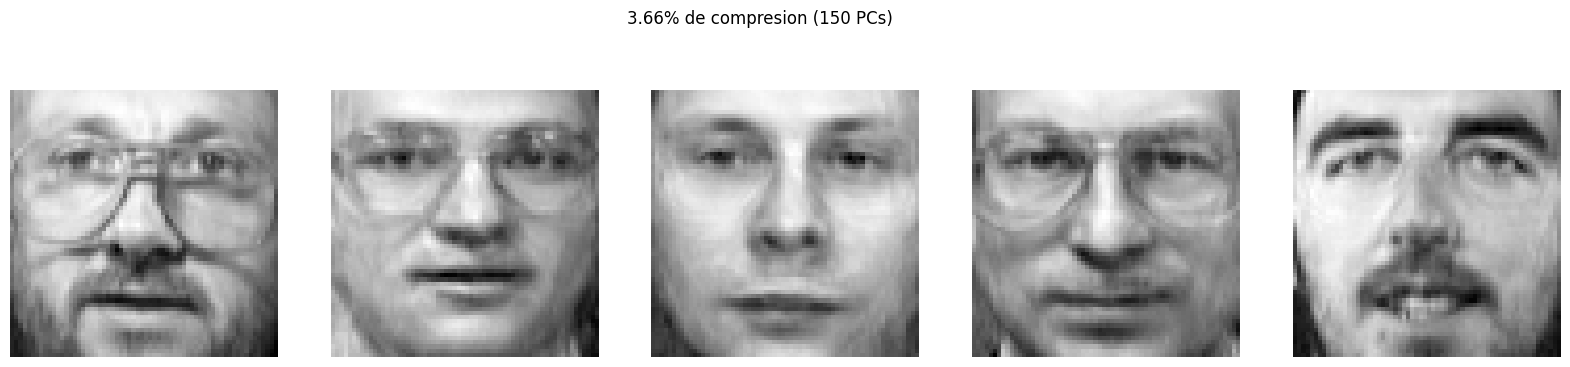

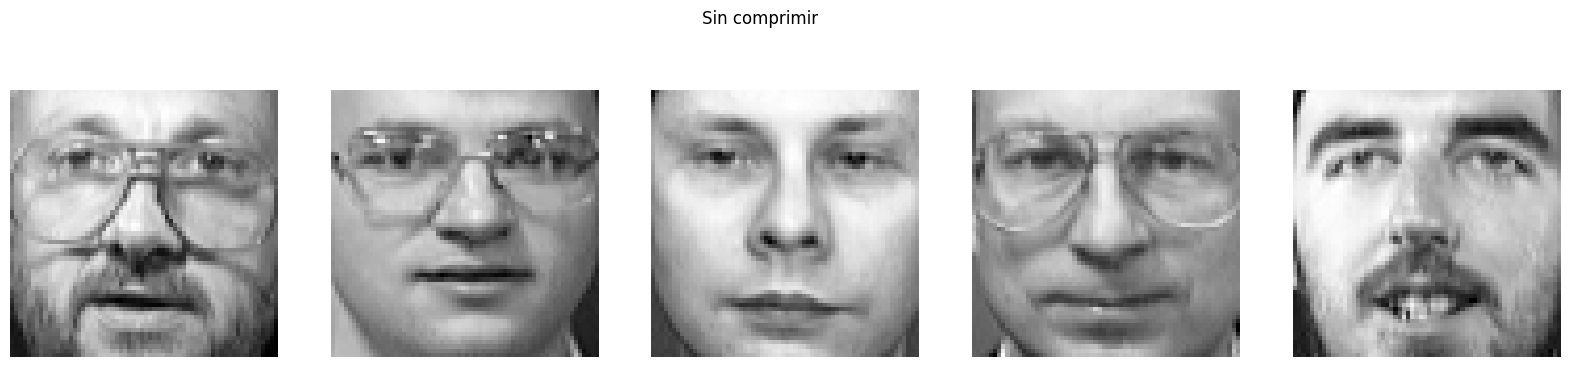

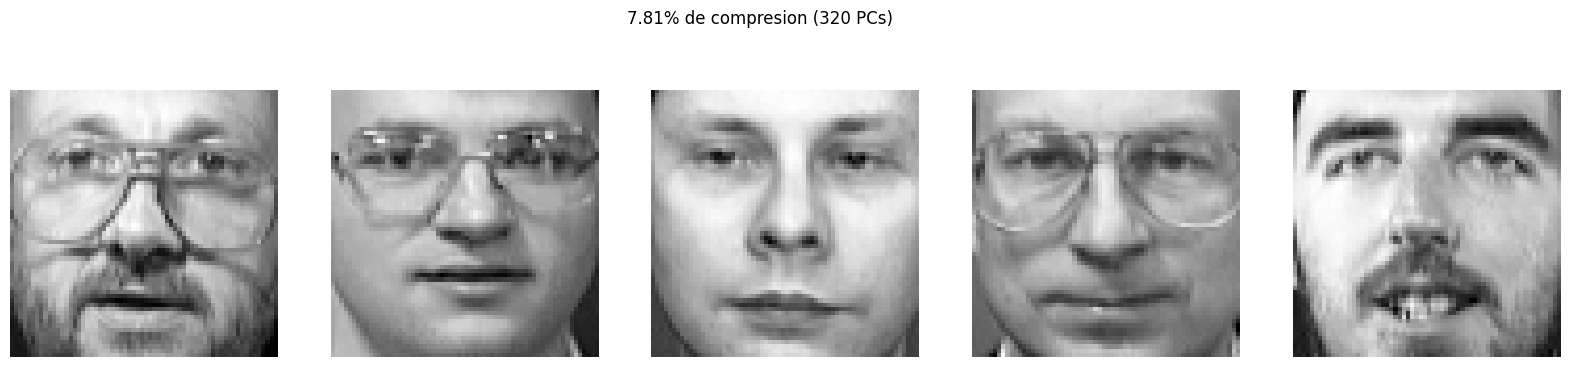

In [54]:
for num_pc in num_pcs + [150,320]: # Añadimos 2 más para que se vea que son las mismas caras :-D
    pca_temp = PCA(num_pc, random_state = 42) # Por una cuestión de funcionamiento de la clase PCA tenemos que "comprimir" de nuevo: no podemos usar el X_train_pca directamente
    X = pca_temp.fit_transform(X_train)
    X_train_temp = pca_temp.inverse_transform(X) # AQUÍ ESTÁ LA CLAVE, primero nos quedamos con el dataset pequeño y luego "descomprimimos"
    pinta_caras(X_train[0:5].values, title = "Sin comprimir")
    pinta_caras(X_train_temp[0:5], title = f"{round(num_pc/num_features*100,2)}% de compresion ({num_pc} PCs)")